# Train balanced COATI on scMultiSim

This notebook reproduces the balanced scMultiSim configuration used for the main comparison: RNA PCA10 is the primary space, ATAC PCA8 is the synchronized secondary space, $C_y=0.1$, and the vector field is trained for 3,000 iterations.

The frozen $T(\mathrm{RNA}, t)\rightarrow\mathrm{ATAC}$ is supplied before trajectory training. The shared UMAP reference is used only after training for visualization.

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import uuid

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.neighbors import KNeighborsRegressor
from threadpoolctl import threadpool_limits

import coati as ct

%matplotlib inline
threadpool_limits(limits=1)
torch.set_num_threads(1)
plt.rcParams.update({"font.family": "Arial", "font.size": 11})

TIME_KEYS = ("time1", "time2", "time3", "time4")
TIME_VALUES = np.arange(4, dtype=float)
RAW_DATA_BASE_URL = "https://raw.githubusercontent.com/shankswang953/COATI/main/examples/data/scmultisim"
SOURCE_FILES = (
    "all_time_scRNA_pca10.npz",
    "all_time_scATAC_pca8_no_pc2.npz",
    "all_time_celltype.npz",
    "primal_norm_params_rna10_w2.pt",
    "secondary_norm_params_atac8_no_pc2_w2.pt",
    "scmultisim_rna10_atac8_film_T.pt",
    "observed_rna10_umap.npz",
)
run_dir = Path("outputs") / ("scmultisim-balanced-cy0p1-" + uuid.uuid4().hex[:8])
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("Training device:", device)

Training device: mps


## Prepare RNA10 and ATAC8

Rows are paired within each time point. COATI stores RNA PCA10 in `obsm["X_pca"]`, ATAC PCA8 in `obsm["X_atac"]`, and the four observed stages in `obs`. No UMAP coordinates enter training.

In [2]:
repo_data_dir = next((
    root / "examples/data/scmultisim" for root in (Path.cwd(), *Path.cwd().parents)
    if (root / "examples/data/scmultisim").is_dir()
), None)
data_dir = repo_data_dir or Path("outputs/scmultisim-data")
data_dir.mkdir(parents=True, exist_ok=True)


def obtain_data(filename):
    path = data_dir / filename
    if not path.is_file():
        print("Downloading", filename)
        urlretrieve(f"{RAW_DATA_BASE_URL}/{filename}", path)
    return path


paired = ct.TemporalData.from_npz(
    obtain_data(SOURCE_FILES[0]), times=TIME_VALUES, keys=TIME_KEYS,
    secondary_path=obtain_data(SOURCE_FILES[1]),
)
with np.load(obtain_data(SOURCE_FILES[2]), allow_pickle=False) as archive:
    celltypes = np.concatenate([archive[key].astype(str) for key in TIME_KEYS])

cells = paired.to_anndata(
    celltype=celltypes, use_rep="X_pca", secondary_key="X_atac", warn=False,
)
cells.obs["stage"] = pd.Categorical(
    np.repeat(TIME_KEYS, [len(x) for x in paired.primary]),
    categories=TIME_KEYS, ordered=True,
)
print(cells)

display(
    cells.obs["stage"].value_counts(sort=False).rename("cells").reset_index()
    .style.hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
)

AnnData object with n_obs × n_vars = 10000 × 10
    obs: 'time', 'celltype', 'barcode', 'stage'
    uns: 'coati_input'
    obsm: 'X_pca', 'X_atac'


stage,cells
time1,2006
time2,2001
time3,3008
time4,2985


## Load the frozen RNA10 → ATAC8 map

This is the same FiLM architecture and checkpoint used by the balanced synchronized run. The map is set to evaluation mode and frozen before COATI training.

In [3]:
class FrozenFiLM(nn.Module):
    def __init__(self, d_in, d_out, hidden=128, n_layers=3, t_hidden=32, dropout=0.0, **_):
        super().__init__()
        self.d_in, self.d_out = d_in, d_out
        self.n_modulated = max(n_layers - 1, 1)
        self.time_encoder = nn.Sequential(
            nn.Linear(1, t_hidden), nn.GELU(),
            nn.Linear(t_hidden, 2 * hidden * self.n_modulated),
        )
        self.input = nn.Linear(d_in, hidden)
        self.hidden = nn.ModuleList(
            nn.Linear(hidden, hidden) for _ in range(self.n_modulated - 1)
        )
        self.output = nn.Linear(hidden, d_out)
        self.activation = nn.GELU()
        self.dropout = nn.Dropout(dropout) if dropout else nn.Identity()

    def forward(self, x, time):
        time = torch.as_tensor(time, dtype=x.dtype, device=x.device)
        time = torch.broadcast_to(time, x.shape[:-1]).unsqueeze(-1)
        film = self.time_encoder(time).reshape(
            *x.shape[:-1], self.n_modulated, 2, self.input.out_features
        )
        h = self.input(x)
        layers = [None, *self.hidden]
        for index, layer in enumerate(layers):
            if layer is not None:
                h = layer(h)
            h = h * (1 + film[..., index, 0, :]) + film[..., index, 1, :]
            h = self.dropout(self.activation(h))
        return self.output(h)


checkpoint = torch.load(obtain_data(SOURCE_FILES[5]), map_location="cpu", weights_only=True)
T = FrozenFiLM(**checkpoint["config"])
state = {
    name.replace("t_encoder", "time_encoder")
        .replace("in_proj", "input")
        .replace("hidden_layers", "hidden")
        .replace("out_proj", "output"): value
    for name, value in checkpoint["state_dict"].items()
}
T.load_state_dict(state)
T.eval().requires_grad_(False)

with torch.no_grad():
    probe = T(torch.tensor(paired.primary[0][:16]), torch.zeros(16))
assert probe.shape == (16, 8) and torch.isfinite(probe).all()
print("Frozen T: RNA10 → ATAC8 | checkpoint epoch:", checkpoint["meta"]["epoch"])

Frozen T: RNA10 → ATAC8 | checkpoint epoch: 285


## Main-figure training configuration

`secondary_weight=0.1` is $C_y$. The density and kinetic-energy coefficients are 10 and 1, respectively. The saved RNA and ATAC normalization parameters reproduce the training coordinates used by the main figure.

In [4]:
config = ct.Config(
    multimodal=True,
    balanced=True,
    iterations=3000,
    batch_size=128,
    learning_rate=1e-4,
    hidden_dim=400,
    n_layers=3,
    activation="leaky_relu",
    secondary_weight=0.1,
    manifold_weight=10.0,
    energy_weight=1.0,
    matching_weight=100.0,
    median_n_sample=128,
    floor_n_sample=128,
    dt=0.1,
    blur_coeff=0.05,
    floor_buffer_std=1.0,
    density_topk=25,
    density_hinge=0.01,
    terminal_density_weight=1.0,
    sync_density_loss=True,
    sync_pdf_loss=True,
    adaptive_lambda=True,
    lambda_min_pri=5.0,
    lambda_min_sec=10.0,
    lambda_max_pri=100.0,
    lambda_max_sec=100.0,
    eta_lambda_pri=10.0,
    eta_lambda_sec=10.0,
    dual_warmup=1000,
    dual_decay=1.0,
    device=device,
    extra={
        "pdf_coefficient_pri": 100.0,
        "pdf_coefficient_sec": 100.0,
        "lambda_init": 100.0,
        "lambda_init_pri": 100.0,
        "lambda_init_sec": 100.0,
    },
)

settings = pd.DataFrame({
    "parameter": ["iterations", "RNA dimensions", "ATAC dimensions", "C_y",
                  "density coefficient", "energy coefficient", "batch size"],
    "value": ["3000", "10", "8", "0.1", "10", "1", "128"],
})
display(
    settings.style.hide(axis="index")
    .set_properties(**{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
)

parameter,value
iterations,3000
RNA dimensions,10
ATAC dimensions,8
C_y,0.1
density coefficient,10
energy coefficient,1
batch size,128


## Train the balanced synchronized vector field

The frozen T is copied into the training result but is never optimized with the vector field. Training runs in RNA PCA10, while ATAC PCA8 contributes the synchronized loss.

In [5]:
result = ct.train_vector_field(
    cells,
    config=config,
    output_dir=run_dir,
    T_model=T,
    use_rep="X_pca",
    secondary_obsm_key="X_atac",
    primal_norm_path=obtain_data(SOURCE_FILES[3]),
    sec_norm_path=obtain_data(SOURCE_FILES[4]),
    verbose=False,
)
print("Completed iterations:", config.to_dict()["niters"])
print("Vector-field checkpoint:", run_dir / "checkpoints/path_param.pth")

Completed iterations: 3000
Vector-field checkpoint: outputs/scmultisim-balanced-cy0p1-23075ccc/checkpoints/path_param.pth


In [6]:
quality = pd.Series(result.evaluate(), name="value").rename_axis("metric").reset_index()
display(
    quality.style.hide(axis="index")
    .format({"value": "{:.4f}"})
    .set_properties(**{"text-align": "left"})
    .set_table_styles([{"selector": "th", "props": [("text-align", "left")]}])
)

metric,value
endpoint_sinkhorn_before,1.2192
endpoint_sinkhorn_after,0.0231
kinetic_energy_mean,1.2570
endpoint_sampling_floor,0.0280
secondary_endpoint_sinkhorn,0.0417


## Project trajectories into the shared RNA10 UMAP

The committed reference UMAP was fitted once on all 10,000 observed RNA PCA10 cells with `n_neighbors=25`, `min_dist=1.0`, `random_state=42`, and `transform_seed=42`. All initial cells are predicted at the four observed times and projected into those fixed coordinates with a 25-neighbor regressor. Each generated cell keeps its initial lineage color.

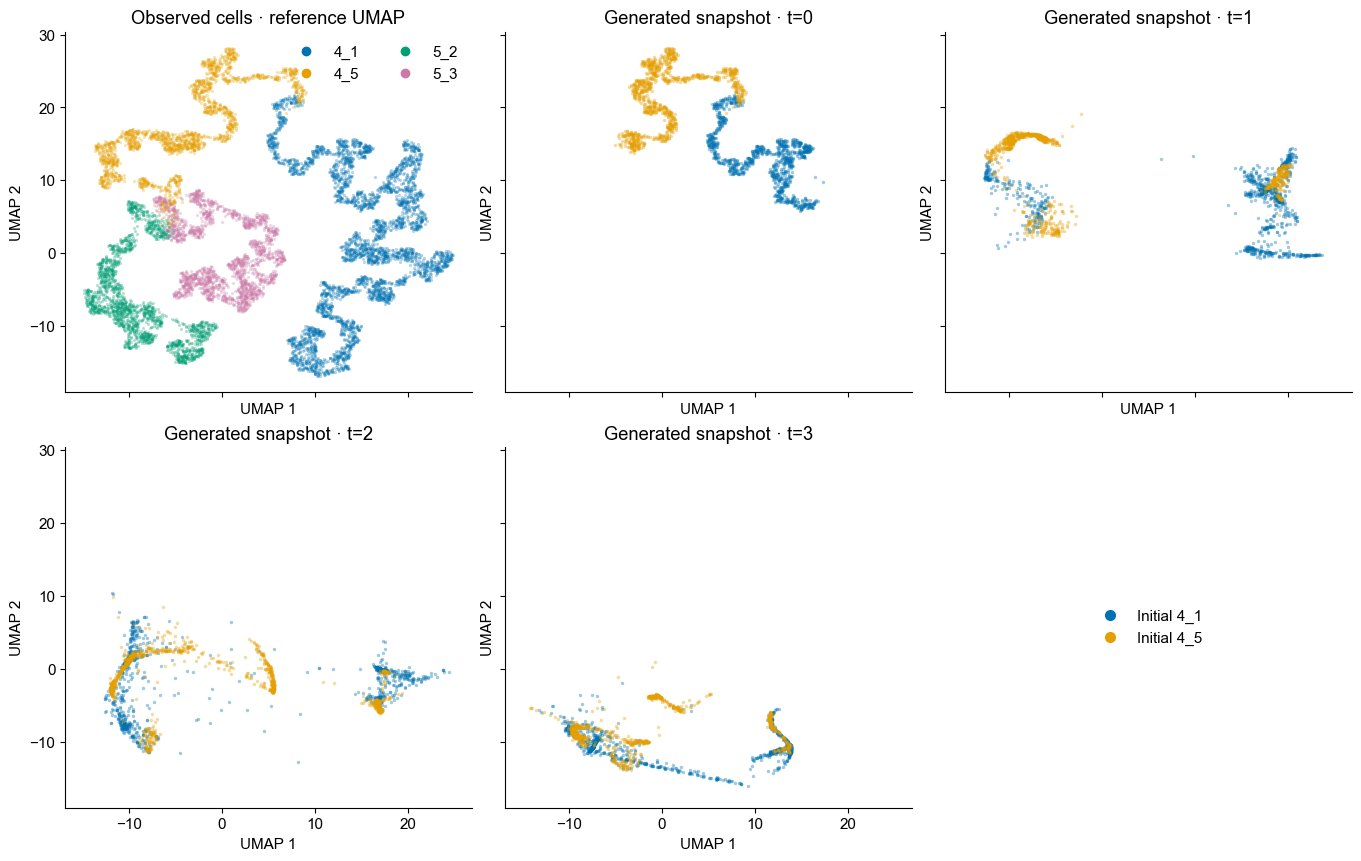

In [ ]:
prediction = result.predict(
    initial=paired.primary[0],
    times=TIME_VALUES,
    raw=True,
)


with np.load(obtain_data(SOURCE_FILES[6]), allow_pickle=False) as archive:
    observed_umap = archive["observed_umap"]
    observed_population = archive["observed_population"].astype(str)
np.testing.assert_array_equal(observed_population, celltypes)

reference_projector = KNeighborsRegressor(n_neighbors=25, weights="distance", n_jobs=-1)
reference_projector.fit(np.concatenate(paired.primary), observed_umap)
projected = reference_projector.predict(prediction["primary"].reshape(-1, 10))
snapshot_umap = projected.reshape(len(TIME_VALUES), len(paired.primary[0]), 2)
initial_lineages = celltypes[:len(paired.primary[0])]

palette = dict(zip(sorted(np.unique(celltypes)), ["#0072B2", "#E69F00", "#009E73", "#CC79A7"]))
fig, axes = plt.subplots(2, 3, figsize=(13.5, 8.5), sharex=True, sharey=True, layout="constrained")
reference_ax = axes[0, 0]
snapshot_axes = (axes[0, 1], axes[0, 2], axes[1, 0], axes[1, 1])
for label in sorted(palette):
    mask = celltypes == label
    reference_ax.scatter(*observed_umap[mask].T, s=5, alpha=.30, linewidths=0,
                         color=palette[label], rasterized=True)
for time, points, ax in zip(TIME_VALUES, snapshot_umap, snapshot_axes):
    for label in sorted(np.unique(initial_lineages)):
        mask = initial_lineages == label
        ax.scatter(*points[mask].T, s=6, alpha=.38, linewidths=0,
                   color=palette[label], rasterized=True)
    ax.set_title(f"Generated snapshot · t={time:g}")
handles = [Line2D([], [], marker="o", linestyle="", color=palette[label], label=label, markersize=6)
           for label in sorted(palette)]
reference_ax.legend(handles=handles, frameon=False, ncol=2)
reference_ax.set_title("Observed cells · reference UMAP")
initial_handles = [Line2D([], [], marker="o", linestyle="", color=palette[label],
                          label=f"Initial {label}", markersize=7)
                   for label in sorted(np.unique(initial_lineages))]
axes[1, 2].legend(handles=initial_handles, frameon=False, loc="center")
axes[1, 2].axis("off")
for ax in (reference_ax, *snapshot_axes):
    ax.set(xlabel="UMAP 1", ylabel="UMAP 2")
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [8]:
print("Training space: RNA PCA10")
print("Visualization only: shared observed-cell UMAP")
print("Run directory:", run_dir)

Training space: RNA PCA10
Visualization only: shared observed-cell UMAP
Run directory: outputs/scmultisim-balanced-cy0p1-23075ccc
